In [55]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import h5py
from pathlib import Path

In [3]:
import tkinter as tk
from tkinter import filedialog

root = tk.Tk()
root.withdraw()
root.attributes('-topmost', True)
gwtools_path = filedialog.askdirectory(title="Select folder of gwtools")

gwtools path

In [117]:
if gwtools_path not in sys.path:
    sys.path.append(gwtools_path)
if 'mantis_utilities' in sys.modules:
    del sys.modules['mantis_utilities']
import mantis_utilities as mnts

Mantis repository path

In [5]:
root = tk.Tk()
root.withdraw()
root.attributes('-topmost', True)
mantis_repo_path = filedialog.askdirectory(title="Select folder of Mantis repository")

Central Valley Mantis data

In [14]:
root = tk.Tk()
root.withdraw()
root.attributes('-topmost', True)
cv_data_path = filedialog.askdirectory(title="Select the folder where the Mantis configuration file is")

Initialize scenario

In [6]:
scenario = mnts.mantis_inputs()

Set the client executable and temporary files for input/output (this file will be overwritten over and over)

In [104]:
scenario['client'] = (Path(mantis_repo_path) / 'CPP/BIN/MantisClient.exe').as_posix()
scenario['infile'] = (Path(os.getcwd()) / 'temp_inputfile.dat').as_posix()
scenario['outfile'] = (Path(os.getcwd()) / 'temp_output_file.dat').as_posix()

Set up scenario in CV
Select study area (only one)

In [8]:
scenario['modelArea'] = 'CentralValley'

Select Region division

In [9]:
#scenario['bMap'] = 'CentralValley' # To run the entire Central Valley
scenario['bMap'] = 'Subregions'

Select Regions

In [144]:
#scenario['Regions'] = ['Subregion1','Subregion2']
scenario['Regions'] = ['Subregion15']

Saturated Flow parameters

In [142]:
scenario['flowScen'] = 'CVHM2_MAR24_Padj'
scenario['wellType'] = 'VD' # or VD
scenario['por'] = 20; # or any of the 10,20,30,40,50

Unsaturated flow parameters

In [16]:
scenario['unsatScen'] = 'CVHM2_MAR24'
scenario['unsatWC'] = 0.2

Simulation period

In [76]:
scenario['startSimYear'] = 1945
scenario['endSimYear'] = 2200

Setting raster loading

First we need the raster information

In [29]:
cv_ras_linear = mnts.read_raster(cv_data_path + '/CV_DATA/CVraster_py.h5')
print(cv_ras_linear.shape)

(21155563, 2)


Convert it to full raster

In [34]:
gs = mnts.mantis_grid_spec('CentralValley')
print(gs)

cv_ras = mnts.convert_column_to_raster(cv_ras_linear, (gs.Nrows, gs.Ncols), -1)

gridSpec(cornerX=-223300, cornerY=-344600, cellSize=50, Nrows=12863, Ncols=7046)


Read the rasterize HRUS

| Watershade code |  Value  |
|:---------------:|:-------:|
|      SACV       | 1000000 |
|       SJV       | 2000000 |
|       TLB       | 3000000 |
|      DM_SUB       | 4000000 |
|      Kings       | 5000000 |

In [46]:
hru_ras_path = cv_data_path + '/../../SWAT_data/SWAT_NPSAT_Feedback_Loop/SALT_LOAD/20250429/MantisSA_inputfiles/'
#hru_ras = np.loadtxt(hru_ras_path + 'HRU_Raster20250429_py.dat')
with h5py.File(hru_ras_path + 'HRU_Raster20250429_py.h5', "r") as f:
    hru_ras = f["HRUs"][:].T

In [48]:
print(hru_ras.shape)
(hru_ras > 5000000).sum()

(21155563,)


np.int64(1559351)

Runtime loading
Setup the loading

In [83]:
test_load = np.zeros(hru_ras.size, dtype=float)
test_load[hru >= 0] = 10
test_load[hru > 3_000_000] = 30
test_load[hru > 5_000_000] = 60

Write it to a location that Mantis Server can access it

In [85]:
loading_file = Path(os.getcwd()) / "test_load.h5"
mnts.write_linear_data(["test_load"], test_load, loading_file, suppress_print = True)

In [78]:
scenario['loadScen'] = 'GNLM_Full' # this will not be used but is needed to avoid errors
scenario["modifierName"] = loading_file.as_posix()
scenario["modifierType"] = "Replace"
scenario["modifierUnit"] = "CONC"  # Use "MASS" if these are mass-loading values.

Run simulation

In [145]:
scenario['denitMap'] = None
scenario["getids"] = False
scenario["getotherinfo"] = False # getids must be True for this to work
btc, well_info, success = mnts.run_mantis(scenario, return_metadata=True)

In [150]:
def plot_percentiles(x, btc, prctl, title):
    prc_btc = np.percentile(btc, axis=0, q=prctl)
    fig, ax = plt.subplots(figsize=(10, 5))
    for i in range(len(prctl) - 1, -1, -1):
        p = prctl[i]
        ax.plot(x,prc_btc[i, :], label=f"{p}%", linewidth=2)
    ax.set_xlabel('Time (years)')
    ax.set_ylabel('Concentration [mg/l]')
    ax.legend()
    ax.set_title(f"{title}")
    ax.grid()

    return prc_btc

In [115]:
selected_precentiles = [25,50,75,90, 95]
x_time = np.arange(scenario['startSimYear'], scenario['endSimYear'])

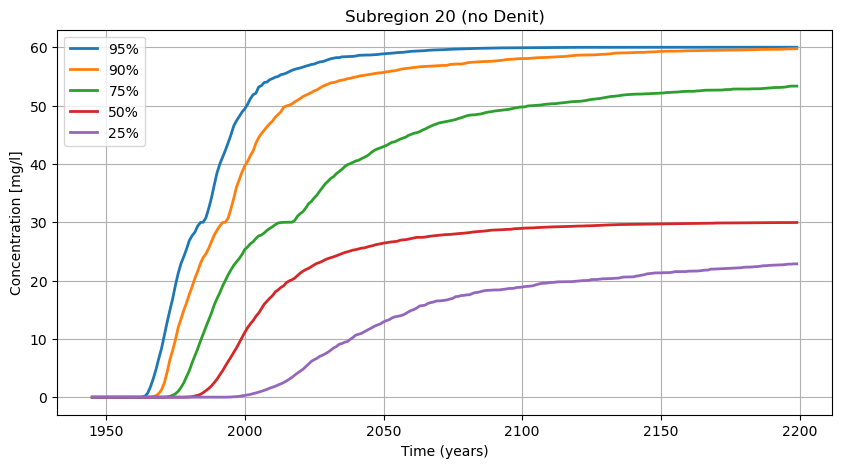

In [151]:
prc_btc = plot_percentiles(x_time, btc, selected_precentiles, "Subregion 20 (no Denit)")

Denitrification

In [162]:
scenario['denitMap'] = 'DO_05_TD150'
scenario["denitThreshold"] = 0.01
scenario["denitFractionRemoved"] = .99

In [163]:
btc_denit, well_info, success = mnts.run_mantis(scenario, return_metadata=True)

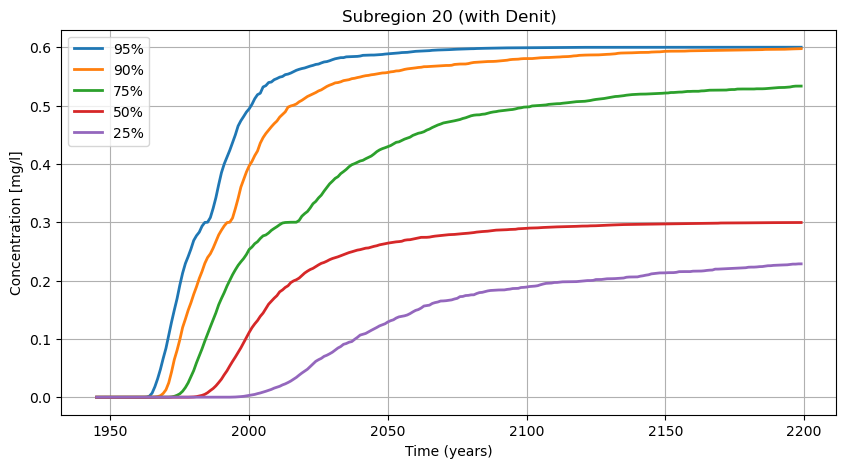

In [164]:
prc_btc_denit = plot_percentiles(x_time, btc_denit, selected_precentiles, "Subregion 20 (with Denit)")


In [ ]:
prc_btc_denit